# 虚実行と合流 ―― 楽観的並行制御・スナップショット分離・AI エージェント

(Version 0.2.1)

**0.2.1 での変更**: 読み直して、定理 B の証明の最後(時間が重なることの不等式)の組み合わせを直し、§7 に report2 の定理 E・E′ との関係を足した。照合の記録の場所を正し、参考文献に report2・report3 を足した。

**0.2.0 での変更**: 定理 B を Lean で証明した。SI の時刻の規則(スナップショットと first-committer-wins)から、依存グラフの循環では「最初に確定したトランザクションに入る二本の辺がどちらも rw で、両端の時間が重なっている」ことを示し(Fekete ら 2005・Cahill ら 2008 の形)、その系として SSI の安全性を示した(§4)。§7 の後続レポートへの参照を report3 に合わせた。

文責: JRF ( http://jrf.cocolog-nifty.com/ ) ／ 執筆・計算の大部分: Claude Opus 5.5 (Anthropic) ／ 2026年11月

**要旨.** 第一報「虚実行論」(以下 report0)では、並列処理の実行を「各クリティカルセクション(CS)がどの状態を読んだか」の木として見て、**実実行 = 状態を移動させた実行、虚実行 = 状態をコピーしてしまった実行** と整理した。虚実行では、コピーされた状態がそれぞれ別の世界で続き、世界は分かれたまま二度と出会わなかった。

この稿では、分かれた世界をもう一度 **合流(マージ)** させる。現実の並列処理には、これをわざとやっている仕組みがたくさんある。データベースのトランザクションは、状態のスナップショット(コピー)の上で並行に動き、終わったら書き込みを現在の状態へ合流させる。Linux の RCU は、書き手が状態を複製して更新している間も、読み手に古い版を読ませる。複数の AI エージェントが、リポジトリのコピー(git の worktree)の上で別々に作業して、あとで merge する。どれも「虚実行をさせておいて、あとでまとめる」やり方である。

問いは一つである: **どんな合流なら、直列に実行したのと見分けがつかなくなるか**。つまり、どんな条件なら、虚実行が観測としては実実行になるか。主な結果は次のとおり。

1. トランザクションを「スナップショットを読み、書き込みを残す CS」として ELDE の枠組みに入れ、合流のある虚実行を総当りするプログラム `kj_txn.py` を作る(§1)。
2. **定理 A**: 各トランザクションが読んだ変数を、それが作業している間に確定した相手が書いていなければ、合流の結果は確定順の直列実行と一致する。これは楽観的並行制御(OCC, Kung & Robinson 1981)の後ろ向き検証の正しさそのもので、**「読んだものがコピーの間に書き換えられていない」ことが、虚実行が実と見分けられない条件** になる。Lean 4 で証明した(§2)。
3. スナップショット分離(SI)は、書き込みの衝突(同じ変数を二つの世界が書く)だけを調べ、読みとの衝突を見ない。そのため、二つの世界がそれぞれ相手の **コピー** を根拠に判断して別々の変数を書くと、合流の結果はどちらの直列順とも一致しない(write skew)。読むだけのトランザクションにさえ、実在しない世界が見えることがある(Fekete ら 2004)。古典的な異常を、規則ごとに総当りで分類する(§3)。
4. SI で直列化できない実行の依存グラフの循環は、必ず「連続する二本の rw 逆依存」を含む(**定理 B**、Fekete ら 2005)。循環の中で最初に確定したトランザクションに目をつけると数行で証明でき、Lean 4 で証明した。ランダムな例の総当りでも確かめる(§4)。
5. 読む側を待たせない仕組み(MVCC・RCU)は、**虚実行を許し、観測を実と区別できない範囲に抑える** 設計である。排他ロックとのトレードオフを確率的なシミュレーションで見る(§5)。
6. 並列に動く AI エージェントの作業の合流も同じ形をしている。テキストの merge は SI と同じく書き込みの衝突しか見ないので、write skew 型の「衝突のない壊れ方」が起きる(§6)。
7. Haskell の callCC で「捨てた世界の成果を、過去の世界に持ち込む」のも、合流の一種である(§7)。

計算はすべてこのノートの中で再現できる(Python 標準ライブラリ+numpy+matplotlib)。定理 A・定理 B と write skew の例は、Lean 4(Mathlib)で形式的に証明し、Lean のコードは各定理の直後に置いて、ノートの最後でまとめて検査する。定理の番号はこのノートの中だけのもので、report0 の定理 1〜4 と区別するために A, B と書く。

## 目次

- §0 report0 のおさらいと、この稿の問い
- §1 合流のある虚実行 ―― トランザクションのモデル
- §2 二つの世界の合流 ―― 定理 A(楽観的並行制御)
- §3 分離レベルの総当り ―― lost update・write skew・read-only anomaly
- §4 依存グラフと危険構造 ―― 定理 B
- §5 読む側を待たせない ―― MVCC と RCU
- §6 並列に動く AI エージェント
- §7 callCC と合流
- §8 まとめと今後の課題
- 参考文献
- 付録 Lean による一括検証

## §0 report0 のおさらいと、この稿の問い

### 0.1 実実行と虚実行

JRF は 2011 年、並列プロセスのロック依存を総当りで調べる Perl プログラム ELDE(Exhaustive Lock Dependency Emulator)を書き、2018 年になって、それが実際にはありえない実行まで数えていたことに気づいて、それを **虚実行** と名付けた。report0 はそれを次のように整理した。

- 各 CS が読んだ状態を書いた CS を親とすると、実行は初期状態 ⊥ を根とする木になる(読み出し関係 rf)。
- **実実行 ⇔ どの状態も高々一度しか読まれない ⇔ 木が一本道**(report0 の定理 1)。実実行は状態を **移動** させる。
- 虚実行は、ある状態を二つ以上の CS が読む実行である。状態は **コピー** され、それぞれ別の世界で続く。世界は分かれたまま合流しない。

report0 はさらに、未来の状態まで読んでよい(非因果的な)実行に階層を延ばし、そこでは実行が「一周して整合するもの」としてしか存在しないことを見た。この稿は、そちらではなく、因果を守ったままコピーと **合流** を許す方向に進む。

### 0.2 合流とは

report0 の虚実行では、コピーされた二つの世界は二度と出会わなかった。ところが現実の並列処理には、わざと状態をコピーし、後で一つにまとめる仕組みが多い。

| 仕組み | コピー | 合流 |
|---|---|---|
| データベースのトランザクション(MVCC、スナップショット分離) | 開始時のスナップショット | 確定(commit)時に書き込みを現在の状態へ |
| 楽観的並行制御(OCC)、ソフトウェア・トランザクショナル・メモリ | 読んだ値の控え | 検証に通ったら書き込みを反映 |
| Linux の RCU(read-copy-update) | 書き手が作る新しい版 | 版の差し替え(古い版は読み手が去るまで残す) |
| git の branch / worktree、並列 AI エージェント | 作業用のコピー | merge |
| Haskell の callCC | 捕まえた継続(過去の世界) | 捨てた世界の値を持って過去に戻る |

合流を許すと、読み出し関係は木ではなく、親を二つ持つ頂点のある **DAG**(有向非巡回グラフ)になる。合流した状態は、「コピーした時点の状態」と「その後に別の世界で起きたこと」の両方を親に持つからである。

### 0.3 この稿の問い

コピーして合流させた実行は、そのままでは虚実行である(コピーがあるので一本道ではない)。しかし、**合流の結果も、各トランザクションが読んだ値も、ある直列の実行(実実行)とまったく同じ** なら、外から見て区別できない。データベースの言葉でいう **直列化可能性**(serializability。Papadimitriou 1979)である。

そこで問いはこうなる: **どんな合流の規則なら、虚実行が観測として実実行と見分けられなくなるか。** 見分けられなくなるとき、虚実行は「速く実行するための仮の姿」として正当化される。見分けられるとき、それは異常(anomaly)と呼ばれる。

## §1 合流のある虚実行 ―― トランザクションのモデル

### 1.1 トランザクション

共有状態は変数から値への対応(辞書)とする。**トランザクション** $t$ は

- 読み集合 $R_t$(読む変数)と書き集合 $W_t$(書く変数)、
- 読んだ値から書く値を決める関数 $f_t$(読み集合の値だけに依存する)

からなる。ELDE の言葉でいえば、トランザクションは一つの CS である。ただし、ロックで排他されるのではなく、他と **並行に** 動く。

実行は、各トランザクションの **開始**(start)と **確定**(commit)の事象の並びで表す(開始が確定より前)。

- 開始のとき、その時点で確定している状態の **スナップショット**(コピー)をとる。
- 確定のとき、スナップショットから計算した書き込みを、**その時点の** 確定状態に上書きする。書き集合の外の変数は、その時点の状態のまま残る。これが **合流** である。

開始と確定の間に他のトランザクションが確定していなければ、スナップショットは確定時の状態と同じで、合流は普通の(直列の)実行になる。**重なりのない並び = 実実行** である。

### 1.2 確定規則

合流させてよいかどうかを確定の時点で判断する規則を、次の四つ用意する。

| 規則 | 確定時に調べること | 由来 |
|---|---|---|
| NOVAL | 何も調べない(いつでも合流) | 検証のない、最も素朴な方式 |
| SI | 自分の作業中に確定した相手と **書き集合** が交わったら中止 | スナップショット分離の first-committer-wins(Berenson ら 1995) |
| OCC | 自分の作業中に確定した相手の書き集合と、自分の **読み集合** が交わったら中止 | 楽観的並行制御の後ろ向き検証(Kung & Robinson 1981) |
| SSI | SI に加え、rw 逆依存が「入る辺と出る辺」の両方を持つトランザクション(危険構造の要)ができたら中止 | 直列化可能スナップショット分離(Cahill ら 2008)を簡略化したもの |

**直列化可能性の判定** は、確定したトランザクションを何かの順に一つずつ(重なりなく)実行して、各トランザクションが読んだ値と最終状態がともに一致する順序があるかを総当りで調べる。

### 1.3 実装

以下のセルは `kj_txn.py` を書き出す。最初は読み飛ばして §1.4 から見てもよい。

In [1]:
# 日本語フォントの設定(Colab では japanize-matplotlib を入れると楽)
import matplotlib
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib  # noqa: F401
except Exception:
    from matplotlib import font_manager
    for name in ["Noto Sans CJK JP", "IPAexGothic", "IPAGothic", "TakaoGothic", "Yu Gothic", "Meiryo"]:
        if any(name == f.name for f in font_manager.fontManager.ttflist):
            matplotlib.rcParams["font.family"] = name
            break
matplotlib.rcParams["axes.unicode_minus"] = False
import numpy as np
import itertools, random
from collections import Counter, defaultdict
print("ok")

ok


#### `kj_txn.py`

トランザクション `Txn`、事象の並び `schedules`、確定規則つきの実行 `run`、直列化可能性の判定 `serial_equivalents`、依存グラフ `dsg`、ランダムなトランザクション `random_txns`、読み手のシミュレーション `sim_readers`。

In [2]:
%%writefile kj_txn.py
# -*- coding: utf-8 -*-
"""kj_txn.py -- 「虚実行と合流」(report1)の計算コア。

トランザクション = スナップショット(状態のコピー)を読み、書き込みを残す CS。
確定(commit)のとき、書き込みを現在の状態へ「合流」させる。
report0 の言葉では、スナップショットを二つ以上のトランザクションが読むのが「コピー」(虚実行)、
確定のときに自分のスナップショット以後の確定を取り込むのが「合流」である。

    t = Txn("T1", R={"x"}, W={"x"}, f=lambda s: {"x": s["x"] + 1})

f はスナップショット(辞書)を受け取り、書き込む変数とその値の辞書を返す。f は R の値だけに依存すること。
"""
from __future__ import annotations
import itertools
from collections import Counter, defaultdict


class Txn:
    def __init__(self, name, R, W, f):
        self.name = name
        self.R = frozenset(R)
        self.W = frozenset(W)
        self.f = f

    def writes(self, snap):
        w = self.f(dict(snap))
        assert set(w) <= self.W, (self.name, w)
        return w

    def __repr__(self):
        return self.name


Overwriting kj_txn.py


In [3]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
# 実行の並び: start_i / commit_i の事象列(start_i が commit_i より前)


Appending to kj_txn.py


In [4]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
def schedules(n):
    """n 個のトランザクションの事象列をすべて作る。事象は ("s", i) / ("c", i)。"""
    out = []

    def rec(seq, started, committed):
        if len(committed) == n:
            out.append(tuple(seq))
            return
        for i in range(n):
            if i not in started:
                rec(seq + [("s", i)], started | {i}, committed)
            elif i not in committed:
                rec(seq + [("c", i)], started, committed | {i})
    rec([], frozenset(), frozenset())
    return out


def is_serial_schedule(sched):
    """重なりのない(start の直後に同じトランザクションの commit が来る)並び = 実実行。"""
    return all(sched[k][0] == "s" and sched[k + 1] == ("c", sched[k][1]) for k in range(0, len(sched), 2))


Appending to kj_txn.py


In [5]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
# 実行: 確定規則ごとの合流


Appending to kj_txn.py


In [6]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
RULES = ("NOVAL", "SI", "SSI", "OCC")


class Run:
    """一つの実行の結果。"""

    def __init__(self):
        self.order = []          # 確定した順のトランザクション番号
        self.aborted = []        # 中止したトランザクション番号
        self.snap = {}           # i -> スナップショット(dict)
        self.snap_ver = {}       # i -> スナップショットの版(それまでに確定した数)
        self.commit_ver = {}     # i -> 確定したときの版番号(確定順で 1, 2, ...)
        self.reads = {}          # i -> R の値(読んだ値)
        self.final = None        # 最終状態
        self.history = []        # 版の列 [(書いたトランザクション, 状態)]、版 0 は初期状態

    def merges(self):
        """合流の数: 確定のとき、自分のスナップショット以後に別の確定があったもの。"""
        return sum(1 for i in self.order if self.commit_ver[i] - 1 != self.snap_ver[i])

    def copies(self):
        """コピーの数: 二つ以上のトランザクションに読まれた版について (読んだ数 - 1) の和。"""
        c = Counter(self.snap_ver[i] for i in self.order)
        return sum(k - 1 for k in c.values() if k > 1)


def run(txns, sched, rule, init):
    """事象列 sched を確定規則 rule で実行する。"""
    assert rule in RULES
    n = len(txns)
    st = dict(init)
    r = Run()
    r.history.append((None, dict(st)))
    start_ver = {}
    rw_in, rw_out = defaultdict(set), defaultdict(set)    # SSI 用: 並行するトランザクション間の rw 逆依存

    def committed_since(i):
        return [j for j in r.order if r.commit_ver[j] > start_ver[i]]

    for kind, i in sched:
        t = txns[i]
        if kind == "s":
            start_ver[i] = len(r.order)
            r.snap[i] = dict(st)
            r.snap_ver[i] = start_ver[i]
            continue
        since = committed_since(i)
        if rule in ("SI", "SSI") and any(txns[j].W & t.W for j in since):
            r.aborted.append(i); continue                 # first-committer-wins
        if rule == "OCC" and any(txns[j].W & t.R for j in since):
            r.aborted.append(i); continue                 # Kung–Robinson の後ろ向き検証
        if rule == "SSI":
            # i と、i の実行中に確定した j: i が読んだ変数を j が書いた → i -rw-> j
            new_out = {j for j in since if t.R & txns[j].W}
            # まだ確定していない i の書き込みを、i より前に始まり i の開始後に確定した j が読んでいた → j -rw-> i
            new_in = {j for j in since if txns[j].R & t.W}
            # 確定済みで i と時間が重なる(i の開始時にまだ確定していなかった)もの全体
            overlap = set(since)
            out_i = rw_out[i] | new_out
            in_i = rw_in[i] | new_in
            pivot = bool(out_i) and bool(in_i)
            for j in new_out:                             # j が新たに in を得て pivot になるか
                pivot |= bool(rw_out[j])
            for j in new_in:                              # j が新たに out を得て pivot になるか
                pivot |= bool(rw_in[j])
            if pivot:
                r.aborted.append(i); continue
            rw_out[i] |= new_out; rw_in[i] |= new_in
            for j in new_out:
                rw_in[j].add(i)
            for j in new_in:
                rw_out[j].add(i)
        w = t.writes(r.snap[i])
        st.update(w)                                      # 合流: 書き込んだ変数だけ上書き
        r.order.append(i)
        r.commit_ver[i] = len(r.order)
        r.reads[i] = {x: r.snap[i].get(x) for x in t.R}
        r.history.append((i, dict(st)))
    r.final = st
    return r


def serial_equivalents(txns, r, init):
    """確定したトランザクションを直列に実行して、読んだ値と最終状態が r と一致する順序をすべて返す。"""
    out = []
    for perm in itertools.permutations(r.order):
        st = dict(init)
        ok = True
        for i in perm:
            if {x: st.get(x) for x in txns[i].R} != r.reads[i]:
                ok = False; break
            st.update(txns[i].writes(st))
        if ok and st == r.final:
            out.append(perm)
    return out


def classify(txns, init, rules=RULES):
    """すべての事象列を各規則で実行し、(全確定, 中止あり, 直列化不能) などを数える。"""
    n = len(txns)
    scheds = schedules(n)
    table = {}
    for rule in rules:
        c = Counter()
        for sc in scheds:
            r = run(txns, sc, rule, init)
            c["schedules"] += 1
            if r.aborted:
                c["with_abort"] += 1
            ser = bool(serial_equivalents(txns, r, init))
            if not ser:
                c["non_serializable"] += 1
            if r.merges():
                c["with_merge"] += 1
                if ser:
                    c["merge_but_serializable"] += 1
        table[rule] = c
    return table


Appending to kj_txn.py


In [7]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
# 依存グラフ(Adya の DSG): wr / ww / rw の辺


Appending to kj_txn.py


In [8]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
def dsg(txns, r):
    """確定したトランザクションの依存グラフ。辺は (a, b, 種類)。

    版は確定順に並ぶ。変数 x の版を書いたトランザクションの列を確定順に取り、
      ww: x を続けて書いた a の次に b
      wr: b がスナップショットで読んだ x の版を書いたのが a
      rw: a が読んだ x の版の、次の版を書いたのが b(a は b の書き込みを見ていない)
    """
    edges = set()
    writers = defaultdict(list)            # x -> [確定順の書き手]
    for i in r.order:
        for x in txns[i].W:
            writers[x].append(i)
    for x, ws in writers.items():
        for a, b in zip(ws, ws[1:]):
            edges.add((a, b, "ww"))
    for b in r.order:
        for x in txns[b].R:
            # b のスナップショットに入っていた x の最後の書き手
            before = [a for a in writers.get(x, []) if r.commit_ver[a] <= r.snap_ver[b]]
            if before:
                edges.add((before[-1], b, "wr"))
            after = [c for c in writers.get(x, []) if r.commit_ver[c] > r.snap_ver[b] and c != b]
            if after:
                edges.add((b, after[0], "rw"))
    return edges


def dsg_cycles(edges, nodes):
    """単純な循環をすべて返す(小さなグラフ用)。各循環は [(a, b, kind), ...]。"""
    adj = defaultdict(list)
    for a, b, k in edges:
        adj[a].append((b, k))
    cycles = []
    nodes = sorted(nodes)

    def dfs(start, u, path, seen):
        for v, k in adj[u]:
            if v == start:
                cycles.append(path + [(u, v, k)])
            elif v not in seen and v > start:
                dfs(start, v, path + [(u, v, k)], seen | {v})
    for s in nodes:
        dfs(s, s, [], {s})
    return cycles


def has_consecutive_rw(cycle):
    ks = [k for _, _, k in cycle]
    return any(ks[i] == "rw" and ks[(i + 1) % len(ks)] == "rw" for i in range(len(ks)))


Appending to kj_txn.py


In [9]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
# ランダムなトランザクション(性質の総当り確認用)


Appending to kj_txn.py


In [10]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
def random_txns(rng, n, vars_=("x", "y", "z"), vals=3, p_read=0.5, p_write=0.4):
    """読み集合・書き集合と、読んだ値の組から書く値への表をランダムに作る。"""
    txns = []
    for k in range(n):
        R = sorted(v for v in vars_ if rng.random() < p_read)
        W = sorted(v for v in vars_ if rng.random() < p_write)
        if not W:
            W = [rng.choice(vars_)]
        table = {}
        for key in itertools.product(range(vals), repeat=len(R)):
            table[key] = {w: rng.randrange(vals) for w in W}

        def f(s, R=tuple(R), table=table):
            return dict(table[tuple(s[x] for x in R)])
        txns.append(Txn(f"T{k + 1}", R, W, f))
    return txns


Appending to kj_txn.py


In [11]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
# 読む側を待たせない(§5): 排他ロックと、版を複製する方式(MVCC・RCU)の比較
#   1 本の書き手が、長さ write_len の更新を休みなく繰り返す。
#   読み手は各時刻に確率 lam で到着し、長さ read_len だけ読む。
#   LOCK: 読み手と書き手は排他(書き手の更新中に来た読み手は待つ。読み手がいる間、書き手は始められない)。
#   COPY: 書き手は版を複製して更新し、終わったら新しい版を公開する。読み手は到着時の最新版を待たずに読む。
#         古い版は、それを読んでいる読み手がいなくなるまで残す(RCU の猶予期間)。


Appending to kj_txn.py


In [12]:
%%writefile -a kj_txn.py
# ------------------------------------------------------------------
def sim_readers(policy, lam, write_len=5, read_len=2, T=20000, seed=0):
    import random
    rng = random.Random(seed)
    readers = []           # [残り時間, 読んでいる版]
    queue = 0              # LOCK で待っている読み手の数
    wait_total = 0
    n_reads = 0
    stale = 0              # 読み終わったとき、より新しい版がすでに公開されていた読み
    version = 0            # 公開済みの最新版
    writer_left = write_len
    writer_active = True   # LOCK で書き手が更新中か
    max_versions = 1
    updates = 0
    for t in range(T):
        if rng.random() < lam:
            queue += 1
        if policy == "COPY":
            while queue:
                readers.append([read_len, version]); queue -= 1; n_reads += 1
            writer_left -= 1
            if writer_left == 0:
                version += 1; updates += 1; writer_left = write_len
        else:  # LOCK
            if writer_active:
                writer_left -= 1
                if writer_left == 0:
                    version += 1; updates += 1; writer_active = False
            if not writer_active:
                while queue:
                    readers.append([read_len, version]); queue -= 1; n_reads += 1
            wait_total += queue
        done = [r for r in readers if r[0] <= 1]
        for r in done:
            if r[1] < version:
                stale += 1
        readers = [[r[0] - 1, r[1]] for r in readers if r[0] > 1]
        if policy == "LOCK" and not writer_active and not readers and not queue:
            writer_active = True; writer_left = write_len
        live = len({r[1] for r in readers} | {version})
        max_versions = max(max_versions, live + (1 if policy == "COPY" else 0))
    return dict(policy=policy, lam=lam, mean_wait=wait_total / max(n_reads, 1),
                stale_frac=stale / max(n_reads, 1), max_versions=max_versions,
                updates_per_1000=1000 * updates / T)


Appending to kj_txn.py


In [13]:
from kj_txn import *
print('ok')

ok


### 1.4 例: 当直の医師(write skew)

病院に医師が二人いて、変数 $x, y$ はそれぞれが当直なら 1、外れたら 0 とする。規則は「少なくとも一人は当直していなければならない」。二人とも当直のとき、それぞれが「もう一人が当直しているので、自分は外れる」というトランザクションを走らせる。

- $T_1$: $x$ と $y$ を読み、$x + y \ge 2$ なら $x \leftarrow 0$。
- $T_2$: $x$ と $y$ を読み、$x + y \ge 2$ なら $y \leftarrow 0$。

二つの事象の並びを比べる。左は重なりのない並び(実実行)、右は二つとも同じスナップショットから出発する並び(虚実行 + 合流)である。図は **版の DAG** で、○ は確定した状態(版)、矢印の実線は「スナップショットとして読んだ」、破線は「合流のとき、その上に書き込んだ」を表す。合流のない確定では二本が重なる。

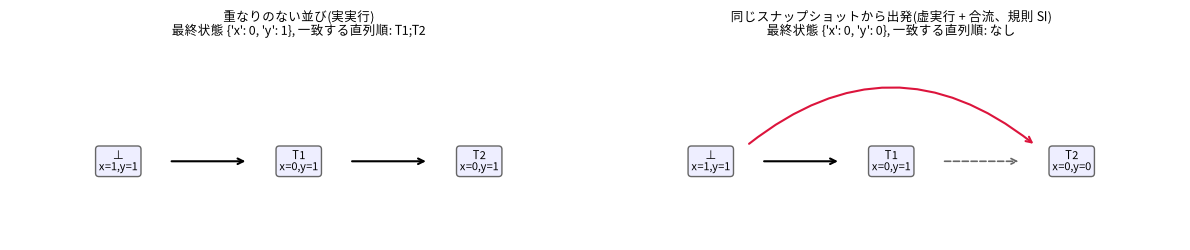

In [14]:
def doctor():
    return [Txn("T1", {"x", "y"}, {"x"}, lambda s: {"x": 0} if s["x"] + s["y"] >= 2 else {}),
            Txn("T2", {"x", "y"}, {"y"}, lambda s: {"y": 0} if s["x"] + s["y"] >= 2 else {})]

def draw_versions(ax, txns, r, title):
    nv = len(r.history)
    for k, (who, st) in enumerate(r.history):
        lab = "⊥" if who is None else txns[who].name
        ax.text(k, 0, f"{lab}\n" + ",".join(f"{a}={b}" for a, b in sorted(st.items())),
                ha="center", va="center", fontsize=8, bbox=dict(boxstyle="round", fc="#eef", ec="0.4"))
    for i in r.order:
        k = r.commit_ver[i]; sv = r.snap_ver[i]
        if sv == k - 1:
            ax.annotate("", xy=(k - .28, 0), xytext=(k - 1 + .28, 0), arrowprops=dict(arrowstyle="->", lw=1.5))
        else:
            ax.annotate("", xy=(k - .2, .12), xytext=(sv + .2, .12),
                        arrowprops=dict(arrowstyle="->", lw=1.5, color="crimson", connectionstyle="arc3,rad=-0.4"))
            ax.annotate("", xy=(k - .28, 0), xytext=(k - 1 + .28, 0),
                        arrowprops=dict(arrowstyle="->", lw=1.2, ls="--", color="0.4"))
    ax.set_xlim(-.6, nv - .4); ax.set_ylim(-.6, .9); ax.axis("off"); ax.set_title(title, fontsize=9)

T = doctor(); init = {"x": 1, "y": 1}
serial = (("s", 0), ("c", 0), ("s", 1), ("c", 1))
overlap = (("s", 0), ("s", 1), ("c", 0), ("c", 1))
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6))
for ax, sc, ttl in [(axes[0], serial, "重なりのない並び(実実行)"), (axes[1], overlap, "同じスナップショットから出発(虚実行 + 合流、規則 SI)")]:
    r = run(T, sc, "SI", init)
    eq = [";".join(T[i].name for i in perm) for perm in serial_equivalents(T, r, init)]
    draw_versions(ax, T, r, ttl + f"\n最終状態 {r.final}, 一致する直列順: {', '.join(eq) or 'なし'}")
plt.tight_layout(); plt.show()

左では $T_2$ が $T_1$ の結果($x=0$)を読むので、$T_2$ は何もしない。右では、$T_1$ と $T_2$ が同じスナップショット($x=y=1$)を **コピー** として読み、それぞれ「もう一人がいる」と判断して別々の変数を書く。合流すると $x=y=0$ で、誰も当直していない。どちらの直列順でも一人は残るので、この結果はどの実実行とも一致しない。書き集合は交わらないので、スナップショット分離の規則(SI)はこれを止めない。

report0 の言葉でいえば、二つの世界はそれぞれ局所的には正しく振る舞った(規則を確かめてから外れた)。破れたのは「同じ状態を二度使わない」という大域的な線形性である。そして合流によって、その破れが一つの状態の中に持ち込まれた。

## §2 二つの世界の合流 ―― 定理 A(楽観的並行制御)

### 2.1 定理 A

確定の順に $t_0, t_1, t_2, \dots$ と番号をつける。$t_k$ のスナップショットは、それまでに確定した $j_k$ 個のトランザクションの結果($j_k \le k$)で、$t_k$ はそれを読んで書き込みを計算し、$k$ 個目までの確定状態に合流する。

**定理 A(合流の直列等価性).** すべての $k$ について、$t_k$ の読み集合が、$t_k$ の作業中に確定した相手 $t_i$($j_k \le i < k$)の書き集合と交わらないとする。このとき、合流による実行のすべての版は、確定順 $t_0, t_1, \dots$ の直列実行の版と一致する。各トランザクションが読んだ値も一致する。

**証明.** 版 $j$ から版 $k$ までに確定したものが変数 $x$ を書いていなければ、$x$ の値は版 $j$ と版 $k$ で変わらない(合流は書き集合の外を変えない)。仮定から、$t_k$ のスナップショット(版 $j_k$)と、確定直前の版 $k$ は、$t_k$ の読み集合の上で一致する。$f_{t_k}$ は読み集合の値だけに依存するから、スナップショットから計算した書き込みは、版 $k$ から計算した書き込み(直列実行での書き込み)と同じである。あとは $k$ についての帰納法で、版が一つずつ一致していく。∎

これは OCC の後ろ向き検証(「自分の作業中に確定した相手が、自分の読んだものを書いていたら中止」)が正しい理由そのものである。虚実行の言葉では、**コピーを読んで作業しても、そのコピーが作業中に古くなっていなければ(読んだ部分について)、合流の結果は実実行と見分けられない**。古くなったかどうかを調べるのは **読み集合** であって、書き集合ではない。

**系(二つのトランザクション).** 共通のスナップショットから出た $T_1, T_2$ を $T_1, T_2$ の順に合流させた結果は、$T_2$ が $T_1$ の書いた変数を読まなければ、直列実行 $T_1;T_2$ と一致する。

逆に §1.4 の当直の例では、$T_2$ は $T_1$ が書いた $x$ を読んでいる($T_1$ も $T_2$ が書いた $y$ を読んでいる)ので、どちらの順でも定理 A の条件が成り立たない。書き集合が交わらないことは、何の保証にもならない。

### 2.2 Lean による証明

状態を関数 `X → V`、トランザクションを `Txn`(読み集合 `R`、書き集合 `W`、書き込む値の関数 `f` と、`f` が `R` の値だけに依存するという性質 `dep`)とする。合流は `merge t snap cur`(`snap` から計算した書き込みを `cur` に上書き)。状態の列 `st` は漸化式 `st (k+1) = merge (ts k) (st (js k)) (st k)` を満たすものとして与え、直列実行 `ser` と比べる。`thmA` が定理 A、`two_txn` が系である。最後の `write_skew` は、§1.4 の当直の例で、書き集合が交わらないのに合流の結果(二人とも外れる)がどちらの直列順(一人は残る)とも一致しないことを示す。

In [15]:
%%writefile test.lean
import Mathlib

set_option autoImplicit false
set_option linter.deprecated false

namespace ImagExec.R1

open Classical

variable {X V : Type}

/-! ## 1. トランザクションと合流

状態は変数 `X` から値 `V` への関数。トランザクション `t` は読み集合 `R`、書き集合 `W` と、
スナップショットから書き込む値を計算する `f` を持つ。`f` は `R` の値だけに依存する(`dep`)。 -/

structure Txn (X V : Type) where
  R : Set X
  W : Set X
  f : (X → V) → X → V
  dep : ∀ s s' : X → V, (∀ x ∈ R, s x = s' x) → ∀ x ∈ W, f s x = f s' x

/-- 合流: スナップショット `snap` から計算した書き込みを、現在の状態 `cur` に上書きする
(書き集合の外は `cur` のまま)。`snap = cur` なら普通の(直列の)実行。 -/
noncomputable def merge (t : Txn X V) (snap cur : X → V) : X → V :=
  fun x => if x ∈ t.W then t.f snap x else cur x


Overwriting test.lean


In [16]:
%%writefile -a test.lean
/-! ## 2. 定理 A: 合流が直列実行と区別できない条件

確定の列 `k = 0, 1, 2, …`。`k` 番目に確定するトランザクション `ts k` は、版 `js k`(それまでに
確定した数、`js k ≤ k`)をスナップショットとして読み、版 `k` に合流して版 `k+1` を作る。
状態の列 `st` はこの漸化式を満たすものとして与える。直列実行 `ser` はスナップショットが常に最新のもの。 -/

/-- 版 `j` から版 `k` までに、書き集合が `x` を含む確定がなければ、`x` の値は変わらない。 -/
theorem unchanged (ts : ℕ → Txn X V) (js : ℕ → ℕ) (st : ℕ → X → V)
    (hst : ∀ k, st (k + 1) = merge (ts k) (st (js k)) (st k)) (x : X) (j : ℕ) :
    ∀ k, j ≤ k → (∀ i, j ≤ i → i < k → x ∉ (ts i).W) → st k x = st j x := by
  intro k hk
  induction k, hk using Nat.le_induction with
  | base => intro _; rfl
  | succ k hjk ih =>
    intro h
    rw [hst k]
    simp only [merge]
    rw [if_neg (h k hjk (Nat.lt_succ_self k))]
    exact ih (fun i hi hik => h i hi (Nat.lt_succ_of_lt hik))

/-- **定理 A.** 各トランザクションの読み集合が、自分のスナップショット以後・自分の確定以前に
確定した相手の書き集合と交わらない(楽観的並行制御の後ろ向き検証)なら、確定順の直列実行と
すべての版が一致する。とくに、各トランザクションが読んだ値も一致する。 -/
theorem thmA (ts : ℕ → Txn X V) (js : ℕ → ℕ) (hjs : ∀ k, js k ≤ k)
    (st ser : ℕ → X → V) (h0 : ser 0 = st 0)
    (hst : ∀ k, st (k + 1) = merge (ts k) (st (js k)) (st k))
    (hser : ∀ k, ser (k + 1) = merge (ts k) (ser k) (ser k))
    (hval : ∀ k i, js k ≤ i → i < k → ∀ x ∈ (ts k).R, x ∉ (ts i).W) :
    (∀ k, st k = ser k) ∧ (∀ k, ∀ x ∈ (ts k).R, st (js k) x = ser k x) := by
  -- スナップショットと最新の版は、読み集合の上で一致する
  have agree : ∀ k, ∀ x ∈ (ts k).R, st (js k) x = st k x := fun k x hx =>
    (unchanged ts js st hst x (js k) k (hjs k) (fun i hi hik => hval k i hi hik x hx)).symm
  have main : ∀ k, st k = ser k := by
    intro k
    induction k with
    | zero => exact h0.symm
    | succ k ih =>
      rw [hst k, hser k, ← ih]
      funext x
      simp only [merge]
      split_ifs with hx
      · exact (ts k).dep _ _ (agree k) x hx
      · rfl
  exact ⟨main, fun k x hx => (agree k x hx).trans (congrFun (main k) x)⟩

/-- 系: 共通のスナップショット `s` から出た二つのトランザクションの合流は、
`T₂` が `T₁` の書いた変数を読まなければ、直列実行 `T₁; T₂` と一致する。 -/
theorem two_txn (t₁ t₂ : Txn X V) (s : X → V) (h : ∀ x ∈ t₂.R, x ∉ t₁.W) :
    merge t₂ s (merge t₁ s s) = merge t₂ (merge t₁ s s) (merge t₁ s s) := by
  funext x
  simp only [merge]
  split_ifs with h2
  · apply t₂.dep
    · intro y hy
      simp only [merge, if_neg (h y hy)]
    · exact h2
  all_goals rfl


Appending to test.lean


In [17]:
%%writefile -a test.lean
/-! ## 3. write skew: 書き集合が交わらなくても、直列実行と一致しない

当直の医師が二人(`x`, `y`、1 なら当直)。どちらのトランザクションも「二人とも当直なら自分を外す」。
共通のスナップショットから両方を確定させると(スナップショット分離の first-committer-wins は
書き集合が交わらないので通す)、二人とも外れる。直列ならどちらの順でも一人は残る。 -/

/-- 変数: `false` が x、`true` が y。 -/
def offDuty (me : Bool) : Txn Bool ℕ where
  R := Set.univ
  W := {me}
  f := fun s v => if v = me ∧ s false + s true ≥ 2 then 0 else s v
  dep := by
    intro s s' h x _
    have h1 := h false (Set.mem_univ _)
    have h2 := h true (Set.mem_univ _)
    have h3 := h x (Set.mem_univ _)
    simp only [h1, h2, h3]

theorem write_skew :
    let s : Bool → ℕ := fun _ => 1
    let si := merge (offDuty true) s (merge (offDuty false) s s)              -- 合流
    let ser₁ := merge (offDuty true) (merge (offDuty false) s s) (merge (offDuty false) s s)
    let ser₂ := merge (offDuty false) (merge (offDuty true) s s) (merge (offDuty true) s s)
    (offDuty false).W ∩ (offDuty true).W = ∅ ∧
      si false + si true = 0 ∧ ser₁ false + ser₁ true = 1 ∧ ser₂ false + ser₂ true = 1 := by
  refine ⟨?_, ?_, ?_, ?_⟩
  · ext x; simp [offDuty]
  all_goals simp [merge, offDuty]

end ImagExec.R1


Appending to test.lean


### 2.3 総当りで確かめる

ランダムに作った 2〜3 個のトランザクション(変数 $x,y,z$、値 0〜2、読み集合・書き集合・書く値の表をランダムに選ぶ)400 組について、ありうる事象の並びをすべて四つの規則で実行し、直列化できない結果が出るかを数える。

In [18]:
rng = random.Random(7)
stats = {rule: Counter() for rule in RULES}
examples = []
for trial in range(400):
    n = rng.choice([2, 3])
    T = random_txns(rng, n)
    init = {"x": 0, "y": 0, "z": 0}
    for sc in schedules(n):
        for rule in RULES:
            r = run(T, sc, rule, init)
            ser = bool(serial_equivalents(T, r, init))
            c = stats[rule]
            c["実行"] += 1
            c["合流あり"] += bool(r.merges())
            c["中止あり"] += bool(r.aborted)
            c["直列化不能"] += (not ser)
            examples.append((T, r, ser, rule))
print(f"{'規則':<6} {'実行':>7} {'合流あり':>8} {'中止あり':>8} {'直列化不能':>10}")
for rule in RULES:
    c = stats[rule]
    print(f"{rule:<6} {c['実行']:>8} {c['合流あり']:>10} {c['中止あり']:>10} {c['直列化不能']:>12}")

規則          実行     合流あり     中止あり      直列化不能
NOVAL     18864      17280          0         7430
SI        18864       7868      14020         1396
SSI       18864       5492      15312            0
OCC       18864       8194      13522            0


OCC(定理 A の条件で中止する規則)と SSI では、直列化できない結果は一つも出ない。どちらも合流のある実行(虚実行)をたくさん通しているが、通したものはすべて観測としては実実行である。NOVAL と SI では、直列化できない結果が出る。SI は NOVAL よりずっと少ないが、ゼロではない。

## §3 分離レベルの総当り ―― lost update・write skew・read-only anomaly

データベースの教科書に出てくる三つの古典的な異常を、四つの規則で総当りする。

- **lost update**(更新の消失): $T_1, T_2$ がともに $x \leftarrow x+1$。同じスナップショットから計算して両方合流させると、$x$ は 2 でなく 1 になる。
- **write skew**: §1.4 の当直の医師。
- **read-only anomaly**(読み取り専用の異常。Fekete, O'Neil, O'Neil 2004): 当座預金 $x$ と普通預金 $y$(はじめ 0)。$T_1$ は普通預金に 20 預ける。$T_2$ は当座から 10 引き出し、引き出すと合計が負になるなら手数料 1 も引く(つまり $x$ と $y$ を読み、$x$ を書く)。$T_3$ は残高を照会するだけ($x, y$ を読み、何も書かない)。

各規則について、ありうる事象の並び(2 個なら 6 通り、3 個なら 90 通り)のうち、合流があったもの、中止があったもの、直列化できない結果になったものを数える。

In [19]:
def lost_update():
    inc = lambda nm: Txn(nm, {"x"}, {"x"}, lambda s: {"x": s["x"] + 1})
    return [inc("T1"), inc("T2")], {"x": 0}

def write_skew():
    return doctor(), {"x": 1, "y": 1}

def read_only():
    return [Txn("T1", {"y"}, {"y"}, lambda s: {"y": s["y"] + 20}),
            Txn("T2", {"x", "y"}, {"x"}, lambda s: {"x": s["x"] - 10 - (1 if s["x"] + s["y"] - 10 < 0 else 0)}),
            Txn("T3", {"x", "y"}, set(), lambda s: {})], {"x": 0, "y": 0}

for name, mk in [("lost update", lost_update), ("write skew", write_skew), ("read-only anomaly", read_only)]:
    T, init = mk()
    print(f"== {name}")
    for rule, c in classify(T, init).items():
        print(f"   {rule:<6} 並び {c['schedules']:>3}  合流あり {c['with_merge']:>3}  中止あり {c['with_abort']:>3}  直列化不能 {c['non_serializable']:>3}")

T, init = read_only()
print("\n(参考)read-only anomaly から照会 T3 を除くと、SI で直列化不能:",
      classify(T[:2], init, rules=("SI",))["SI"]["non_serializable"])

== lost update
   NOVAL  並び   6  合流あり   4  中止あり   0  直列化不能   4
   SI     並び   6  合流あり   0  中止あり   4  直列化不能   0
   SSI    並び   6  合流あり   0  中止あり   4  直列化不能   0
   OCC    並び   6  合流あり   0  中止あり   4  直列化不能   0
== write skew
   NOVAL  並び   6  合流あり   4  中止あり   0  直列化不能   4
   SI     並び   6  合流あり   4  中止あり   0  直列化不能   4
   SSI    並び   6  合流あり   0  中止あり   4  直列化不能   0
   OCC    並び   6  合流あり   0  中止あり   4  直列化不能   0
== read-only anomaly
   NOVAL  並び  90  合流あり  84  中止あり   0  直列化不能   4
   SI     並び  90  合流あり  84  中止あり   0  直列化不能   4
   SSI    並び  90  合流あり  80  中止あり  44  直列化不能   0
   OCC    並び  90  合流あり  46  中止あり  60  直列化不能   0

(参考)read-only anomaly から照会 T3 を除くと、SI で直列化不能: 0


- **lost update** は SI で防がれる。二つの世界が同じ変数 $x$ を書くので、first-committer-wins で一方が中止される。
- **write skew** は SI では防がれない。二つの世界が別々の変数を書くからである。OCC と SSI は防ぐ。
- **read-only anomaly** では、更新する $T_1, T_2$ だけなら SI でも直列化できる($T_2$ を先にすればよい)。ところが照会するだけの $T_3$ が、$T_1$ の確定後・$T_2$ の確定前のスナップショットを読むと、$T_3$ は「預金は入ったが引き出しはまだ」の世界を見る。これは「$T_1$ が $T_2$ より先」を意味するが、$T_2$ は手数料を取られており「$T_2$ が $T_1$ より先」を意味する。**何も書かない観測者にさえ、どの実実行にもない世界が見える。** report0 の言葉でいえば、観測者が一つの枝(世界)を覗いたとき、その枝が、全体として一本道に並べられない木の一部になっている。

具体的に、直列化できない並びを一つ表示しておく。

In [20]:
T, init = read_only()
for sc in schedules(3):
    r = run(T, sc, "SI", init)
    if not serial_equivalents(T, r, init):
        print("事象の並び:", " ".join(f"{k}{T[i].name}" for k, i in sc))
        for i in r.order:
            print(f"   {T[i].name}: スナップショット {r.snap[i]} を読み、確定後の状態 {r.history[r.commit_ver[i]][1]}")
        break

事象の並び: sT1 sT2 cT1 sT3 cT2 cT3
   T1: スナップショット {'x': 0, 'y': 0} を読み、確定後の状態 {'x': 0, 'y': 20}
   T2: スナップショット {'x': 0, 'y': 0} を読み、確定後の状態 {'x': -11, 'y': 20}
   T3: スナップショット {'x': 0, 'y': 20} を読み、確定後の状態 {'x': -11, 'y': 20}


`s` は開始、`c` は確定。$T_3$ は $x=0, y=20$ を読む(預金は入ったが引き出しはまだ)。しかし $T_2$ は $x=y=0$ のスナップショットで判断して手数料を取った。

### 3.2 規則の違いは「何のコピーを調べるか」

四つの規則を虚実行の言葉で並べると、違いは **合流のとき、どのコピーが古くなっていないかを調べるか** にある。

| 規則 | 調べること | 虚実行の言葉で |
|---|---|---|
| NOVAL | 何も | コピーをそのまま合流させる |
| SI | 書き集合の衝突 | 同じ変数を二つの世界が書き換えたときだけ止める |
| OCC | 読み集合と、作業中に確定した相手の書き集合 | 自分が読んだコピーが古くなっていたら止める(定理 A) |
| SSI | SI + 危険構造 | 古くなったコピーを読んだ世界が、さらに別の世界に古いコピーを読ませているときに止める(§4) |

OCC は安全だが、読むだけのトランザクションも中止させうる(上の read-only の例で、OCC は 90 通りのうち 60 通りで中止を出している)。SSI は「危険な形」だけを止めるので、中止が少ない。

## §4 依存グラフと危険構造 ―― 定理 B

### 4.1 直列化グラフ

Adya(1999)は、分離レベルを、確定したトランザクションの間の依存グラフ(DSG)で定義した。変数 $x$ について、

- **ww**: $a$ が書いた $x$ の版の、次の版を $b$ が書いた。
- **wr**: $b$ が読んだ $x$ の版を $a$ が書いた。
- **rw**(逆依存): $a$ が読んだ $x$ の版の、次の版を $b$ が書いた($a$ は $b$ の書き込みを見ていない)。

辺はどれも「直列に並べるなら $a$ が $b$ より前」を意味する。グラフに循環がなければ、位相的に並べた順序が直列実行になる(直列化可能)。

虚実行の言葉では、**rw の辺が「コピー」の痕跡** である。$a$ が読んだのは、$b$ が書く前の古いコピーだった、ということを表している。

**定理 B(Fekete ら 2005).** スナップショット分離のもとで、直列化できない実行の依存グラフには循環があり、その循環は **連続する二本の rw 辺** を含む(「危険構造」。その真ん中のトランザクションを pivot と呼ぶ)。

**証明.** SI の二つの規則から、辺の両端の時刻について次が言える($s_t$ は $t$ の開始、$c_t$ は確定の時刻)。

- ww の辺 $a \to b$: 同じ変数を書くので first-committer-wins により時間が重ならず、$a$ の版が先なので $c_a < s_b$。
- wr の辺 $a \to b$: $b$ のスナップショットに $a$ の書き込みが見えたので $c_a < s_b$。
- rw の辺 $a \to b$: $a$ は $b$ の書き込みを見ていないので $s_a < c_b$。

循環の中で **最初に確定した** トランザクションを $t_2$ とする。$t_2$ に入る辺 $t_1 \to t_2$ が rw でなければ $c_{t_1} < s_{t_2} < c_{t_2}$ で、$t_2$ が最初であることに反する。よって rw で、$s_{t_1} < c_{t_2}$。$t_1$ に入る辺 $t_0 \to t_1$ が rw でなければ $c_{t_0} < s_{t_1} < c_{t_2}$ で、やはり反する。よって rw である。さらに、$t_2$ が最初に確定したので $c_{t_2} \le c_{t_0}$ かつ $c_{t_2} \le c_{t_1}$ である。$t_0$ と $t_1$ については、rw の辺から $s_{t_0} < c_{t_1}$、また $s_{t_1} < c_{t_2} \le c_{t_0}$ なので、時間が重なっている。$t_1$ と $t_2$ については、rw の辺から $s_{t_1} < c_{t_2}$、また $s_{t_2} < c_{t_2} \le c_{t_1}$ なので、やはり時間が重なっている。∎

これは Fekete ら(2005)と Cahill ら(2008)が述べている形(危険構造の両側の相手は pivot と並行に動いていて、出ていく側は循環の中で最初に確定する)そのものである。Lean では、SI の実行の時刻と読み書き `SIRun`、依存グラフの辺 `Edge` を定義し、辺の時刻の性質 `nonrw_time`・`rw_time` から `thmB` を示した。SSI の規則(並行な相手との rw が入って出ていくトランザクションを許さない)なら循環が作れないこと、すなわち直列化可能になること(依存グラフが非巡回なら直列化可能、という Adya の結果と合わせて)が系 `ssi_safe` である。

In [21]:
%%writefile -a test.lean
namespace ImagExec.R1

/-! ## 4. 定理 B: スナップショット分離の危険構造(Fekete ら 2005)

トランザクション `t` は時刻 `s t` に開始(スナップショットをとる)し、`c t` に確定する。事象の時刻はどれも違う。
スナップショット分離(SI)の二つの規則:

* **スナップショット**: `b` が読むのは、`s b` より前に確定した版だけ。
* **first-committer-wins**: 同じ変数を書く二つのトランザクションは、時間が重ならない。

依存グラフ(Adya 1999)の辺を、版の言葉で次のように書く(Adya の定義の辺は、どれもこの条件を満たす)。

* `ww a b`: `a` と `b` が同じ変数を書き、`a` の版が先(`c a < c b`)。
* `wr a b`: `b` が読んだ版を `a` が書いた。`b` に見えるので `c a < s b`。
* `rw a b`: `a` が読んだ変数の、`a` に見えたどの版より後の版を `b` が書いた(`a` は `b` の書き込みを見ていない)。 -/

/-- SI の実行の時刻と読み書き。 -/
structure SIRun (T X : Type) where
  s : T → ℕ
  c : T → ℕ
  W : T → Set X
  R : T → Set X
  sc : ∀ t, s t < c t
  dist : ∀ t u, s t ≠ c u
  fcw : ∀ a b x, a ≠ b → x ∈ W a → x ∈ W b → c a < s b ∨ c b < s a

inductive Kind
  | ww
  | wr
  | rw
  deriving DecidableEq

variable {T X : Type}

/-- 依存グラフの辺。 -/
def Edge (M : SIRun T X) : Kind → T → T → Prop
  | Kind.ww, a, b => a ≠ b ∧ ∃ x, x ∈ M.W a ∧ x ∈ M.W b ∧ M.c a < M.c b
  | Kind.wr, a, b => a ≠ b ∧ ∃ x, x ∈ M.R b ∧ x ∈ M.W a ∧ M.c a < M.s b
  | Kind.rw, a, b => a ≠ b ∧ ∃ x, x ∈ M.R a ∧ x ∈ M.W b ∧
      ∀ w, x ∈ M.W w → M.c w < M.s a → M.c w < M.c b

/-- 時間が重なる(並行に動いた)。 -/
def Concurrent (M : SIRun T X) (a b : T) : Prop := M.s a < M.c b ∧ M.s b < M.c a

/-- rw 以外の辺は、前のトランザクションの確定が後のトランザクションの開始より前。 -/
theorem nonrw_time (M : SIRun T X) {k : Kind} {a b : T} (hk : k ≠ Kind.rw) (h : Edge M k a b) :
    M.c a < M.s b := by
  cases k with
  | ww =>
    obtain ⟨hab, x, ha, hb, hc⟩ := h
    rcases M.fcw a b x hab ha hb with h1 | h1
    · exact h1
    · have := M.sc a; omega
  | wr => exact h.2.choose_spec.2.2
  | rw => exact absurd rfl hk

/-- rw の辺は、前のトランザクションの開始が後のトランザクションの確定より前(`a` は `b` を見ていない)。 -/
theorem rw_time (M : SIRun T X) {a b : T} (h : Edge M Kind.rw a b) : M.s a < M.c b := by
  obtain ⟨_, x, _, hb, hall⟩ := h
  rcases lt_or_gt_of_ne (M.dist a b) with h1 | h1
  · exact h1
  · exact absurd (hall b hb h1) (lt_irrefl _)

/-- 周期 `m` の列。 -/
theorem periodic_mod {α : Type} (v : ℕ → α) (m : ℕ) (hv : ∀ i, v (i + m) = v i) (j : ℕ) :
    v j = v (j % m) := by
  have : ∀ q r, v (r + m * q) = v r := by
    intro q
    induction q with
    | zero => intro r; simp
    | succ q ih => intro r; rw [Nat.mul_succ, ← Nat.add_assoc, hv, ih]
  conv_lhs => rw [← Nat.mod_add_div j m]
  exact this _ _

/-- **定理 B(Fekete ら 2005、Cahill ら 2008 の形).** SI のもとで、依存グラフの循環
(長さ `m`、`i` 番目の辺は `v i` から `v (i+1)`)には、続く二本の rw 辺 `v i →rw v (i+1) →rw v (i+2)` があり、
`v (i+2)` は循環の中で最初に確定したトランザクションで、どちらの rw 辺の両端も時間が重なっている。 -/
theorem thmB (M : SIRun T X) (v : ℕ → T) (k : ℕ → Kind) (m : ℕ) (hm : 1 ≤ m)
    (hv : ∀ i, v (i + m) = v i) (he : ∀ i, Edge M (k i) (v i) (v (i + 1))) :
    ∃ i, k i = Kind.rw ∧ k (i + 1) = Kind.rw ∧
      Concurrent M (v i) (v (i + 1)) ∧ Concurrent M (v (i + 1)) (v (i + 2)) ∧
      ∀ j, M.c (v (i + 2)) ≤ M.c (v j) := by
  obtain ⟨j0, -, hj0⟩ := Finset.exists_min_image (Finset.range m) (fun j => M.c (v j))
    ⟨0, Finset.mem_range.mpr (by omega)⟩
  have hmin : ∀ j, M.c (v j0) ≤ M.c (v j) := by
    intro j
    rw [periodic_mod v m hv j]
    exact hj0 _ (Finset.mem_range.mpr (Nat.mod_lt _ (by omega)))
  set i := j0 + 2 * m - 2 with hi
  have h2 : v (i + 2) = v j0 := by
    have : i + 2 = j0 + m + m := by omega
    rw [this, hv, hv]
  -- 最初に確定した v (i+2) に入る辺は rw
  have k1 : k (i + 1) = Kind.rw := by
    by_contra hk
    have := nonrw_time M hk (he (i + 1))
    have := M.sc (v (i + 2))
    have := hmin (i + 1)
    rw [h2] at *
    omega
  have t1 := rw_time M (k1 ▸ he (i + 1))
  -- その前の辺も rw
  have k0 : k i = Kind.rw := by
    by_contra hk
    have := nonrw_time M hk (he i)
    have := hmin i
    rw [h2] at t1
    omega
  have t0 := rw_time M (k0 ▸ he i)
  refine ⟨i, k0, k1, ⟨t0, ?_⟩, ⟨t1, ?_⟩, fun j => h2 ▸ hmin j⟩
  · have := hmin i
    rw [h2] at t1
    omega
  · have := M.sc (v (i + 2))
    have := hmin (i + 1)
    rw [h2] at *
    omega

/-- **系(SSI).** rw の辺が入ってきて rw の辺が出ていき、どちらも時間の重なる相手との辺であるような
トランザクション(危険構造の要)を一つも許さなければ、依存グラフに循環はない(直列化可能)。 -/
theorem ssi_safe (M : SIRun T X)
    (hnp : ∀ u t w, Edge M Kind.rw u t → Edge M Kind.rw t w →
      Concurrent M u t → Concurrent M t w → False)
    (v : ℕ → T) (k : ℕ → Kind) (m : ℕ) (hm : 1 ≤ m)
    (hv : ∀ i, v (i + m) = v i) (he : ∀ i, Edge M (k i) (v i) (v (i + 1))) : False := by
  obtain ⟨i, k0, k1, c0, c1, -⟩ := thmB M v k m hm hv he
  exact hnp _ _ _ (k0 ▸ he i) (k1 ▸ he (i + 1)) c0 c1

end ImagExec.R1


Appending to test.lean


次のセルで、§2.3 と同じランダムな例で確かめる。あわせて、依存グラフに循環がなければ直列化できることも確かめる。

In [22]:
cnt = {rule: Counter() for rule in RULES}
for T, r, ser, rule in examples:
    E = dsg(T, r)
    cyc = dsg_cycles(E, r.order)
    c = cnt[rule]
    c["直列化不能"] += (not ser)
    c["循環なしで直列化不能"] += (not ser and not cyc)
    c["循環あり"] += bool(cyc)
    c["二本続く rw を含まない循環"] += sum(1 for x in cyc if not has_consecutive_rw(x))
    c["循環があるが値の上では直列化可能"] += (bool(cyc) and ser)
for rule in RULES:
    print(rule, dict(cnt[rule]))

# 定理 B の強い形: 循環の中で最初に確定したトランザクションに入る二本の辺が rw で、両端の時間が重なっている
def concurrent(r, a, b):
    return r.commit_ver[b] > r.snap_ver[a] and r.commit_ver[a] > r.snap_ver[b]
ok = bad = 0
for T, r, ser, rule in examples:
    if rule != "SI":
        continue
    for cyc in dsg_cycles(dsg(T, r), r.order):
        m = len(cyc)
        j = min(range(m), key=lambda i: r.commit_ver[cyc[i][1]])     # cyc[j] の終点が最初に確定
        e1, e0 = cyc[j], cyc[(j - 1) % m]
        good = (e1[2] == "rw" and e0[2] == "rw" and concurrent(r, e0[0], e0[1]) and concurrent(r, e1[0], e1[1]))
        ok += good; bad += (not good)
print(f"SI の循環 {ok + bad} 個: 最初に確定したものに入る二本が並行な rw である {ok}、そうでない {bad}")

NOVAL {'直列化不能': 7430, '循環なしで直列化不能': 0, '循環あり': 12228, '二本続く rw を含まない循環': 13786, '循環があるが値の上では直列化可能': 4798}
SI {'直列化不能': 1396, '循環なしで直列化不能': 0, '循環あり': 2764, '二本続く rw を含まない循環': 0, '循環があるが値の上では直列化可能': 1368}
SSI {'直列化不能': 0, '循環なしで直列化不能': 0, '循環あり': 0, '二本続く rw を含まない循環': 0, '循環があるが値の上では直列化可能': 0}
OCC {'直列化不能': 0, '循環なしで直列化不能': 0, '循環あり': 0, '二本続く rw を含まない循環': 0, '循環があるが値の上では直列化可能': 0}
SI の循環 3236 個: 最初に確定したものに入る二本が並行な rw である 3236、そうでない 0


- どの規則でも、「循環がないのに直列化できない」実行はない(依存グラフが非巡回なら直列化可能)。
- SI では、直列化できない実行にはすべて循環があり、**どの循環も連続する二本の rw 辺を含む**(定理 B)。しかも、循環の中で最初に確定したトランザクションに入る二本がそうなっていて、両端の時間が重なっている(証明の形どおり)。NOVAL では、そうでない循環も多い(lost update の ww と rw の循環など)。
- 「循環があるのに、値の上では直列化できる」実行もある。依存グラフは「どの変数をどの順に読み書きしたか」だけで判断するが、ランダムな表では、たまたま書く値が同じになることがあるからである(依存グラフによる判定は、値によらない保守的な判定)。

SSI(Cahill ら 2008)は、定理 B を逆に使う。pivot になりうる形(rw の辺が入ってきて、rw の辺が出ていく)ができたら中止すれば、循環は作れない。§2.3 で SSI が直列化できない結果を一つも出さなかったのはそのためである。PostgreSQL の SERIALIZABLE はこの方式で実装されている(Ports & Grittner 2012)。

虚実行の言葉で言い直すと、**危険構造とは、古いコピーを読んだ世界(rw の辺の始点)が、さらに別の世界に古いコピーを読ませる(rw の辺の終点)という、コピーの二段重ね** である。コピーが一段なら、合流の順序を工夫すれば実実行に並べ直せる。二段重なると、並べ直せないことがある。

## §5 読む側を待たせない ―― MVCC と RCU

### 5.1 設計の考え方

読み手がとても多く、書き手が少ないデータ(ルーティング表、設定、カーネルの内部構造など)では、読み手を待たせたくない。排他ロックを使うと、書き手の更新中に来た読み手は待たされ、逆に読み手が絶えないと書き手がいつまでも更新できない(書き手の飢餓)。

Linux の RCU(McKenney & Slingwine 1998)と、データベースの MVCC(多版同時実行制御。Bernstein & Goodman 1983)は、**状態を複製する** ことでこれを解く。書き手は新しい版を作って差し替え、読み手は到着した時点の最新版を待たずに読む。古い版は、それを読んでいる読み手がいなくなるまで(RCU の猶予期間)残しておく。

これは **虚実行を許す** 設計である。書き手が新しい版を作っている間に、読み手は古い版(コピー)を読んで進む。同じ版を何人もの読み手が読む。それでも、各読み手が見るのは確定したどれか一つの版なので、「その読み手は、その版を作った更新の直後に、ほかと重ならずに実行された」と並べ直せる。つまり観測は直列化でき、**実実行と区別できない範囲に抑えられている**。失うのは、実時間の順序(読み終わったときにはすでに新しい版が出ているかもしれない)である。これは Herlihy & Wing(1990)の線形化可能性(linearizability)を、直列化可能性まで弱めたことにあたる。

### 5.2 シミュレーション

書き手が 1 本、長さ 5 の更新を休みなく繰り返す。読み手は各時刻に確率 $\lambda$ で到着し、長さ 2 だけ読む。

- **LOCK**: 読み手と書き手は排他。書き手の更新中に来た読み手は待ち、読み手が残っている間は書き手は次の更新を始められない。
- **COPY**(RCU・MVCC 型): 書き手は複製して更新し、終わったら公開する。読み手は待たない。

読み手の平均待ち時間、書き手の更新の回数、読み終わったときにすでに新しい版が出ていた読み(古い版を読んだ割合)、同時に存在した版の数の最大を比べる。

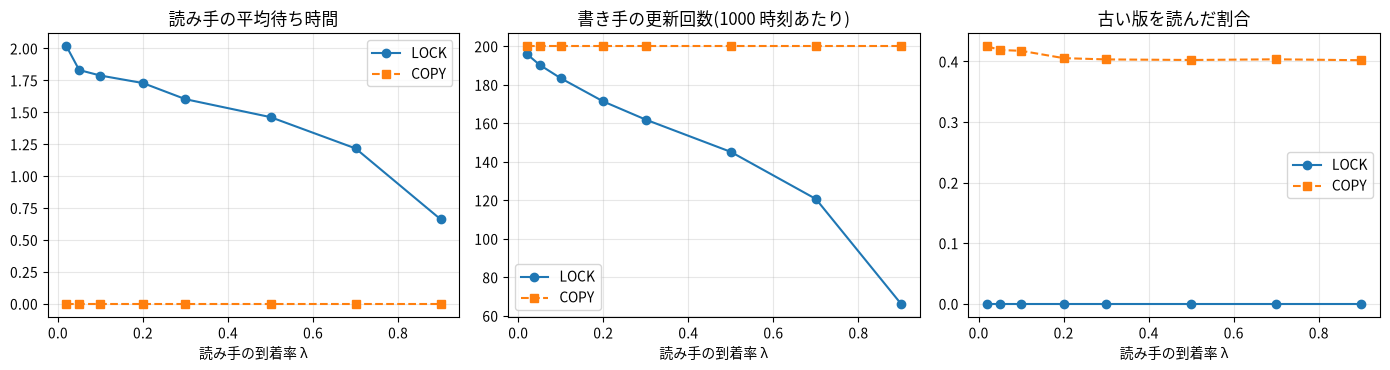

同時に存在した版の数の最大: {'LOCK': 1, 'COPY': 3}
読む長さを変えたときの版の数の最大(COPY, λ=0.5): {1: 2, 2: 3, 5: 3, 10: 4, 20: 6}


In [23]:
lams = [0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
res = {p: [sim_readers(p, lam) for lam in lams] for p in ["LOCK", "COPY"]}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for p, st in [("LOCK", "o-"), ("COPY", "s--")]:
    axes[0].plot(lams, [d["mean_wait"] for d in res[p]], st, label=p)
    axes[1].plot(lams, [d["updates_per_1000"] for d in res[p]], st, label=p)
    axes[2].plot(lams, [d["stale_frac"] for d in res[p]], st, label=p)
axes[0].set_title("読み手の平均待ち時間"); axes[1].set_title("書き手の更新回数(1000 時刻あたり)")
axes[2].set_title("古い版を読んだ割合")
for ax in axes:
    ax.set_xlabel("読み手の到着率 λ"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()
print("同時に存在した版の数の最大:", {p: max(d["max_versions"] for d in res[p]) for p in res})
print("読む長さを変えたときの版の数の最大(COPY, λ=0.5):",
      {L: sim_readers("COPY", 0.5, read_len=L)["max_versions"] for L in [1, 2, 5, 10, 20]})

- **LOCK** では、読み手が増えると書き手が更新できなくなる(更新回数が大きく落ちる)。読み手の待ち時間は、λ が大きいと逆に短くなるが、それは書き手が飢えているからである。データは常に最新だが、その最新が更新されない。
- **COPY** では、読み手は決して待たず、書き手も全速で更新できる。代わりに、読みのかなりの割合が「読み終わったときにはもう古い版」を読み、版を同時に複数持つ必要がある。読む時間が長いほど、残しておく版は増える。

つまり、**待ち時間(排他)と、版の数・鮮度(コピー)を交換している**。虚実行を許す量をどこまで増やせるかは、観測が実実行と区別できない(直列化できる)範囲に収まるかで決まる。読むだけなら一つの版を読めば一貫している。しかし §3 の read-only anomaly が示すとおり、読み手が **更新するトランザクションと絡む** と、古い版を読むことが直列化できない観測につながりうる。

## §6 並列に動く AI エージェント

### 6.1 同じ形

複数の AI エージェントに並行して作業させるとき、よく使われるのは、各エージェントにリポジトリのコピー(git の branch や worktree)を渡し、終わったら merge するやり方である。これはトランザクションそのものである。

- エージェントの作業開始時のリポジトリ = スナップショット。
- エージェントが参照したファイル = 読み集合、変更したファイル = 書き集合。
- merge = 合流。テキストの merge は、同じ箇所を二人が書き換えたときだけ衝突とする。これは **SI の first-committer-wins と同じく、書き込みの衝突しか見ない**。

JRF は日記で、AI を「デバッガ越しに」動かす枠組みを考えるなかで、この形に何度か触れている。

> コンテクストを保存して、同じコンテクストを別の処理で試すみたいな callcc 的なことがだいたい可能だ(2025-05-28)
>
> 複数 AI ラップデバッガを走らせることになるはずだが、その間でのタスクの達成状況を共有するにはどうするか…。git でブランチ分けて…とかもできるのかもしれないが、そうではなく、専門のタスク管理ツール(やデータベースなど)を使うことになるのかもしれない(2025-06-15)
>
> ブランチを作って、その経過はメインの messages に残さず、結果だけマージする…みたいなのがいいのだろうか?(2025-09-20)

### 6.2 衝突のない壊れ方

二人のエージェントが同じリポジトリから作業を始める。

- エージェント A は「関数 `f` はもう誰も呼んでいないので削除する」。`app.py` に `f` の呼び出しがないことを確かめ(読む)、`lib.py` から `f` を消す(書く)。
- エージェント B は「`f` を使って新機能を書く」。`lib.py` に `f` があることを確かめ(読む)、`app.py` に `f` の呼び出しを足す(書く)。

書いたファイルが別々なので、テキストの merge は衝突なしに通る。合流した結果は、存在しない `f` を呼ぶ。これは write skew である。直列に作業すれば、後のエージェントは前の結果を見て判断するので、どちらの順でも壊れない。

In [24]:
def agents():
    A = Txn("A(f を削除)", {"app"}, {"lib"},
            lambda s: {"lib": "f なし"} if s["app"] != "f を呼ぶ" else {})
    B = Txn("B(f を使う)", {"lib"}, {"app"},
            lambda s: {"app": "f を呼ぶ"} if s["lib"] == "f あり" else {"app": "代わりの g を呼ぶ"})
    return [A, B], {"lib": "f あり", "app": "f を呼ばない"}

def broken(st):
    return st["app"] == "f を呼ぶ" and st["lib"] == "f なし"

T, init = agents()
for rule, label in [("SI", "テキストの merge(書き込みの衝突だけ見る)"),
                    ("OCC", "読んだファイルが変わっていたら作業をやり直す(rebase して再確認)")]:
    print(f"== {label}")
    for sc in schedules(2):
        r = run(T, sc, rule, init)
        tag = "壊れた" if broken(r.final) else "正常"
        ab = ", ".join(T[i].name for i in r.aborted) or "なし"
        print(f"   {' '.join(k + str(i) for k, i in sc):<14} 最終 {r.final}  中止 {ab}  → {tag}")

== テキストの merge(書き込みの衝突だけ見る)
   s0 c0 s1 c1    最終 {'lib': 'f なし', 'app': '代わりの g を呼ぶ'}  中止 なし  → 正常
   s0 s1 c0 c1    最終 {'lib': 'f なし', 'app': 'f を呼ぶ'}  中止 なし  → 壊れた
   s0 s1 c1 c0    最終 {'lib': 'f なし', 'app': 'f を呼ぶ'}  中止 なし  → 壊れた
   s1 s0 c0 c1    最終 {'lib': 'f なし', 'app': 'f を呼ぶ'}  中止 なし  → 壊れた
   s1 s0 c1 c0    最終 {'lib': 'f なし', 'app': 'f を呼ぶ'}  中止 なし  → 壊れた
   s1 c1 s0 c0    最終 {'lib': 'f あり', 'app': 'f を呼ぶ'}  中止 なし  → 正常
== 読んだファイルが変わっていたら作業をやり直す(rebase して再確認)
   s0 c0 s1 c1    最終 {'lib': 'f なし', 'app': '代わりの g を呼ぶ'}  中止 なし  → 正常
   s0 s1 c0 c1    最終 {'lib': 'f なし', 'app': 'f を呼ばない'}  中止 B(f を使う)  → 正常
   s0 s1 c1 c0    最終 {'lib': 'f あり', 'app': 'f を呼ぶ'}  中止 A(f を削除)  → 正常
   s1 s0 c0 c1    最終 {'lib': 'f なし', 'app': 'f を呼ばない'}  中止 B(f を使う)  → 正常
   s1 s0 c1 c0    最終 {'lib': 'f あり', 'app': 'f を呼ぶ'}  中止 A(f を削除)  → 正常
   s1 c1 s0 c0    最終 {'lib': 'f あり', 'app': 'f を呼ぶ'}  中止 なし  → 正常


テキストの merge(SI)では、二人が同じスナップショットから出発した並びで、衝突なしに壊れたリポジトリができる。読んだファイルが作業中に変わっていたら作業をやり直す規則(OCC。git でいえば、merge の前に rebase して、エージェントが前提にしていたファイルが変わっていないか確かめ、変わっていればやり直させる)なら、壊れない。

ここから、並列エージェントの合流について実用的な提案ができる。

1. エージェントに、**変更したファイルだけでなく、判断の根拠にしたファイル(読み集合)も申告させる**。
2. 合流のときは書き込みの衝突だけでなく、**自分の読み集合が、作業中に他のエージェントの書き込みで変わっていないか** を調べる(定理 A)。変わっていれば、新しい状態の上でやり直させる。
3. 読み集合が大きすぎて中止ばかりになるなら、危険構造(§4)だけを調べる SSI 型の規則にする。

CI(テストの自動実行)を merge の後に走らせるのは、合流の結果が実実行と区別できるかを、事後に一部だけ調べることにあたる。定理 A は、それを事前に、読み書きの集合だけで保証する方法を与える。

## §7 callCC と合流

JRF は 2011 年に、Haskell の `callCC`(現在の継続を捕まえる仕組み)で goto や「排中律」を書いた(《Haskell の callCC で goto を作る》《時間泥棒の夕べ》)。そこではこう書いている。

> callCC が返す「値」が何度も「なかったこと」にされているわけだが、そこの「成果」を一部引き継ぐことには成功すると言える。
>
> 中の環境は「死んだ夢の世界」のように捨てられるわけだ。ただし、中の環境から値は返すことができる

捕まえた継続 $k$ は「過去のある時点の世界の写し」である。後から $k(v)$ を呼ぶと、今の世界は捨てられ、過去の世界が値 $v$ を持って再開する。これは、**捕まえた時点のスナップショットに、捨てた世界で作った $v$ を合流させる** ことにあたる。継続を一度だけ再開するなら状態は移動するだけで(実実行)、二度以上再開すると同じ過去を何度も読む(コピー、虚実行)。そして $k(v)$ の $v$ が、コピーした世界どうしをつなぐ合流になる。世界の数は 1 + 継続を余分に再開した回数になる(report2 §8 の定理 E)。ただしこれは、状態が継続の中にしかない一本の逐次プログラムの場合で、複数のプロセスが状態を受け渡す場合は、継続を一度ずつしか使わなくても状態の値のコピーで虚実行が作れる(report2 §8.5 の定理 E′)。

違いは、トランザクションの合流が「スナップショット以後に確定した変更」を取り込むのに対し、callCC の合流は「スナップショットそのもの」に戻って、捨てた世界からは $v$ だけを持ち込む点である。古い世界の変数はすべて捕まえた時点の値に戻るので、定理 A の言葉でいえば、捨てた世界の書き込みは $v$ 以外すべて失われる(「死んだ夢の世界」)。

JRF の goto の例で、サーバーに "stop" を送ると、サーバーの `return` は「サーバーを受け取った直後のクライアント」に戻り、クライアントは同じ要求をまた送り、終わらない(GHC 9.10.3 で実測。出力なし、CPU を使い続け、メモリは一定。JRF 自身もソースに "fails into infinite loop" と注記していた)。合流した先の世界が、合流を引き起こした要求をもう一度出すので、合流が同じ形で繰り返される。この「同じ過去に何度も戻る反復」は、report3(時間ループと最適化)§3 で、時間ループの自己無撞着な解が終わらない世界の列として現れるものとして扱った。

## §8 まとめと今後の課題

### 8.1 まとめ

- コピーした世界を合流させる仕組み(トランザクション、MVCC・RCU、git の merge、callCC)は、すべて「虚実行 + 合流」として一つのモデルで書ける(§1)。
- 合流の結果が実実行と見分けられないための条件は、**各世界が読んだコピーが、その世界の作業中に古くなっていないこと**(定理 A。Lean で証明)。調べるべきは書き込みの衝突ではなく、読みと書きの衝突である。
- 書き込みの衝突しか調べない合流(スナップショット分離、テキストの merge)は、二つの世界がそれぞれ相手のコピーを根拠に判断する write skew を通してしまう。読むだけの観測者にさえ、実在しない世界が見えることがある(§3)。
- そのような異常は、必ず「古いコピーを読んだ世界が、別の世界に古いコピーを読ませる」二段重ねの形を含む(定理 B。Lean で証明し、総当りでも確認)。そこだけを止めれば(SSI)、中止を減らしつつ直列化可能にできる(§4)。
- 読む側を待たせない設計(MVCC・RCU)は、虚実行を許して待ち時間を版の数・鮮度と交換し、観測を直列化できる範囲に抑えるものである(§5)。
- 並列 AI エージェントの作業の合流も同じで、読み集合を申告させて定理 A の条件を調べれば、衝突のない壊れ方を防げる(§6)。

report0 の要約と合わせると、次のように言える。**虚実行は、局所的には正しく、大域的な線形性だけを破った実行である。合流は、その破れを一つの状態の中に持ち込む。合流してもなお実実行と見分けられないのは、破れた線形性(コピー)が、どの世界の判断にも使われなかったときである。**

### 8.2 今後の課題

1. **合流の階層.** report0 の虚実行の階層(実 ⊂ E0 ⊂ トンネル ⊂ 因果的コピー)に、合流規則(なし・SI・SSI・OCC・直列化可能)を掛け合わせた階層の全体像。Adya の分離レベルの階層(PL-1, PL-2, PL-2.99, PL-SI, PL-3)との対応。
2. **「依存グラフが非巡回なら直列化可能」(Adya)の Lean 化.** 定理 B は依存グラフの循環についての定理で、直列化可能性そのものとの橋渡しは文献の結果と総当りに頼っている。版と読みの値まで形式化すれば、SSI の安全性を直列化可能性として直接述べられる。
3. **値による直列化可能性と、依存グラフによる判定の差.** §4 で見た「循環があるのに値の上では直列化できる」実行は、虚実行の重み(report0 の母関数の $x$)で数えるとどう見えるか。
4. **CRDT と結果整合性.** 合流の演算そのものを、どの順に合流しても同じ結果になるよう設計する(Shapiro ら 2011)。これは直列化可能性とは別の、「合流の可換性」による解決である。
5. **AI エージェントの合流の実装.** 読み集合の申告と検証を、実際のエージェントの作業(git の worktree と merge)で試す。

## 参考文献

### JRF の文献

- JRF《Exhaustive Lock Dependency Emulator その１ 並列処理の総当り》JRF のソフトウェア Tips, 2011-06-20(追記 2018-04-06)。 http://jrf.cocolog-nifty.com/software/2011/06/post-1.html
- JRF《Exhaustive Lock Dependency Emulator その３ 修正とチェック》同, 2018-04-13。 http://jrf.cocolog-nifty.com/software/2018/04/post-1.html
- JRF《Haskell の callCC で goto を作る》同, 2011-01-20。 http://jrf.cocolog-nifty.com/software/2011/01/post-2.html (配布物 momo_hs-20110214.shar)
- JRF《時間泥棒の夕べ − 排中律と call/cc》JRF の私見：雑記, 2011-01-20。 http://jrf.cocolog-nifty.com/column/2011/01/post-1.html
- JRF の日記(「JRF のひとこと」)2025-05-28(AI のデバッガ越しの実行と callcc 的なコンテクスト保存)、2025-06-15(並列エージェントと git のブランチ)、2025-09-20(ブランチを作り結果だけマージする)。
- JRF & Claude Opus 5.5『虚実行論 ―― 並列処理の総当りから「虚」の理論へ』(report0)、『虚実行があるからこそ解ける問題 ―― 部品の意味と計算量』(report2)、『時間ループと最適化』(report3)。

### トランザクションと並行制御

- C. H. Papadimitriou, "The serializability of concurrent database updates", *Journal of the ACM* 26(4), 631–653, 1979.
- H. T. Kung, J. T. Robinson, "On optimistic methods for concurrency control", *ACM TODS* 6(2), 213–226, 1981.
- P. A. Bernstein, N. Goodman, "Multiversion concurrency control — theory and algorithms", *ACM TODS* 8(4), 465–483, 1983.
- H. Berenson, P. Bernstein, J. Gray, J. Melton, E. O'Neil, P. O'Neil, "A critique of ANSI SQL isolation levels", *SIGMOD* 1995, 1–10.
- A. Adya, *Weak Consistency: A Generalized Theory and Optimistic Implementations for Distributed Transactions*, PhD thesis, MIT, 1999(MIT-LCS-TR-786)。
- A. Fekete, E. O'Neil, P. O'Neil, "A read-only transaction anomaly under snapshot isolation", *SIGMOD Record* 33(3), 12–14, 2004.
- A. Fekete, D. Liarokapis, E. O'Neil, P. O'Neil, D. Shasha, "Making snapshot isolation serializable", *ACM TODS* 30(2), 492–528, 2005.
- M. J. Cahill, U. Röhm, A. D. Fekete, "Serializable isolation for snapshot databases", *SIGMOD* 2008, 729–738.
- D. R. K. Ports, K. Grittner, "Serializable snapshot isolation in PostgreSQL", *Proc. VLDB Endowment* 5(12), 1850–1861, 2012.
- M. Herlihy, J. E. B. Moss, "Transactional memory: architectural support for lock-free data structures", *ISCA* 1993, 289–300.
- P. E. McKenney, J. D. Slingwine, "Read-copy update: using execution history to solve concurrency problems", *Parallel and Distributed Computing and Systems* 1998, 509–518.
- M. Herlihy, J. Wing, "Linearizability: a correctness condition for concurrent objects", *ACM TOPLAS* 12(3), 1990.
- M. Shapiro, N. Preguiça, C. Baquero, M. Zawirski, "Conflict-free replicated data types", *SSS* 2011.

### Lean

- L. de Moura, S. Ullrich, "The Lean 4 theorem prover and programming language", *CADE-28*, 2021. / The mathlib Community, "The Lean mathematical library", *CPP* 2020.

### 謝辞と注意

本稿の枠組み(虚実行 + 合流、定理 A の読み方、危険構造の「コピーの二段重ね」としての読み方、§6 の提案)は、Claude Opus 5.5 が report0 と JRF の記事・日記をもとに組み立てたものである。定理 A・定理 B と write skew の例は Lean 4 + Mathlib で証明した。定理 B の Lean の証明は、SI の規則を時刻の不等式として表したモデルの中のもので、依存グラフの辺の定義は Adya の定義が満たす条件として弱めて書いた(Adya の辺はこの条件を満たすので、結論は Adya の依存グラフにもそのまま当てはまる)。「非巡回なら直列化可能」は文献の結果と総当りによる。SSI の規則は Cahill らの方式を簡略化したもの(確定時に、時間の重なる確定済みトランザクションとの rw 逆依存だけを見る)で、実装そのものではない。文献は照合した(照合の記録は report1/refs_BIBLIO.md)。

## 付録: Lean による一括検証

ここまでの `%%writefile` セルで `test.lean` が出来上がっている。最後に、使った公理を表示する行を足し、Lean 4(v4.34.1)+ Mathlib(v4.34.1)をそろえてまとめて検証する。

* **Colab**: elan をインストールし、`imagexec_lean/` に Mathlib を依存に持つ Lake プロジェクトを作る。`lake exe cache get` でビルド済みの .olean を取得する(初回は数分)。
* **ローカル**: カレントディレクトリかその親に、すでに Mathlib 入りの `lakefile.lean` があれば、それをそのまま使う。

エラーがなく、`#print axioms` が標準の公理(`propext`, `Classical.choice`, `Quot.sound`)だけを挙げれば、証明は通っている。

In [25]:
%%writefile -a test.lean
#print axioms ImagExec.R1.thmA
#print axioms ImagExec.R1.two_txn
#print axioms ImagExec.R1.write_skew
#print axioms ImagExec.R1.thmB
#print axioms ImagExec.R1.ssi_safe


Appending to test.lean


In [26]:
%%bash
set -e
export PATH="$HOME/.elan/bin:$PATH"
if [ -f lakefile.lean ] && grep -q mathlib lakefile.lean; then
  echo "using the existing Lake project in the current directory"
  echo "." > .leandir
elif [ -f ../lakefile.lean ] && grep -q mathlib ../lakefile.lean; then
  echo "using the existing Lake project in the parent directory"
  echo ".." > .leandir
else
  if ! command -v lake >/dev/null 2>&1; then
    curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh \
      | sh -s -- -y --default-toolchain none
  fi
  mkdir -p imagexec_lean && cd imagexec_lean
  echo 'leanprover/lean4:v4.34.1' > lean-toolchain
  cat > lakefile.lean <<'EOF'
import Lake
open Lake DSL

package imagexec_lean

require mathlib from git
  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"
EOF
  lake update 2>&1 | tail -3
  lake exe cache get 2>&1 | tail -3
  cd ..
  echo "imagexec_lean" > .leandir
fi

using the existing Lake project in the parent directory


In [27]:
%%bash
export PATH="$HOME/.elan/bin:$PATH"
LEANDIR=$(cat .leandir)
FILE=$(pwd)/test.lean
cd "$LEANDIR"
time lake env lean "$FILE" && echo "=== test.lean: all theorems checked ==="


'ImagExec.R1.thmA' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R1.two_txn' 

depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R1.write_skew' depends on axiom

s: [propext, Classical.choice, Quot.sound]
'ImagExec.R1.thmB' depends on axioms: [propext, Classical

.choice, Quot.sound]
'ImagExec.R1.ssi_safe' depends on axioms: [propext, Classical.choice, Quot.soun

d]



real	0m2.798s
user	0m2.091s
sys	0m0.927s


=== test.lean: all theorems checked ===
